# Setup

In [1]:
import scvi
import scrnatools as rna
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import cellhint
import os
import shutil
import anndata as ad
import scanpy as sc

/conda-global-envs/sc-genomics/lib/python3.10/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_categorical_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/conda-global-envs/sc-genomics/lib/python3.10/site-packages/docrep/decorators.py:43: SyntaxWarning: 'param_continuous_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


In [2]:
# Setup seeds
scvi.settings.seed = 0

Seed set to 0


## Set data paths

### demeter

In [3]:
rawDataPath = "/mnt/iacchus/joe/raw_data/"
processedDataPath = "/mnt/iacchus/joe/processed_data/"

# Import raw data

## Anderson 2025

In [4]:
anderson = sc.read(f"{processedDataPath}Fezf2_thymus_paper/h5ad_files/combined_all_genes_TECs_final.h5ad")

In [5]:
anderson_lung_epi = sc.read(f"{processedDataPath}Fezf2_thymus_paper/h5ad_files/thymus_lung_epithelial_cell_subset.h5ad")

In [6]:
anderson.obs.subclustered = anderson.obs.subclustered.astype(str)
anderson.obs.loc[anderson_lung_epi.obs.index, "subclustered"] = anderson_lung_epi.obs.lung_subset_annotations
anderson.obs.subclustered = anderson.obs.subclustered.astype("category")

In [7]:
anderson.obs = anderson.obs[["batch", "genotype", "subclustered"]].copy()
anderson.obs = anderson.obs.rename(columns={"subclustered": "original_cell_type"})
anderson.obs["dataset"] = "Anderson_2025"
anderson.obs.batch = anderson.obs.batch.astype(str) + "_" + anderson.obs.dataset

In [8]:
anderson.var = anderson.var[[]]

In [9]:
anderson.obs["sample"] = "CD45- EpCAM+"
anderson.obs["strain"] = "C57BL/6"
anderson.obs["age"] = "4-6wk"

In [10]:
anderson.X = anderson.layers["raw_counts"]

## Ponting 2020

In [11]:
ponting = sc.read(f"{processedDataPath}Fezf2_thymus_paper/h5ad_files/dhalla_reprocessing_TECs.h5ad")

In [12]:
ponting.obs = ponting.obs[["batch", "sample", "majority_voting"]].copy()
ponting.obs["genotype"] = "WT"

In [13]:
sample_dict = {
    "B6-1": "CD45- EpCAM+, Ly51-",
    "B6-2": "CD45- EpCAM+, Ly51-",
    "BC-2": "CD45- EpCAM+, Ly51-",
    "B6-8-TSPAN8-": "CD45- EpCAM+ Ly51- Tspan8-",
    "B6-10-TSPAN8+": "CD45- EpCAM+ Ly51- Tspan8+",
    "BC-1": "CD45- EpCAM+ Ly51-",
    "B6-7-GP2+": "CD45- EpCAM+ Ly51- Gp2+",
    "F1-4-GP2+": "CD45- EpCAM+ Ly51- Gp2+",
    "B6-4": "CD45- EpCAM+ Ly51-",
    "F1-3-GP2+": "CD45- EpCAM+ Ly51- Gp2+",
    "F1-3-GP2-": "CD45- EpCAM+ Ly51- Gp2-",
    "B6-9-TSPAN8+": "CD45- EpCAM+ Ly51- Tspan8+",
    "F1-1_2-GP2+": "CD45- EpCAM+ Ly51- Gp2+",
    "B6-6-GP2+": "CD45- EpCAM+ Ly51- Gp2+",
    "B6-5": "CD45- EpCAM+, Ly51-",
    "B6-3": "CD45- EpCAM+, Ly51-",
    "F1-4-GP2-": "CD45- EpCAM+ Ly51- Gp2-",
    "B6-10-TSPAN8-": "CD45- EpCAM+ Ly51- Tspan8-",
    "B6-9-TSPAN8-": "CD45- EpCAM+ Ly51- Tspan8-",
    "B6-8-TSPAN8+": "CD45- EpCAM+ Ly51- Tspan8+"
}
strain_dict = {
    "B6": "C57BL/6",
    "BC": "BALB/c",
    "F1": "C57BL/6 × BALB/c F1"
}

In [14]:
ponting.obs["sample"] = ponting.obs["batch"].replace(sample_dict)
ponting.obs["strain"] = [i.split("-")[0] for i in ponting.obs["batch"]]
ponting.obs.strain = ponting.obs.strain.replace(strain_dict)
ponting.obs["dataset"] = "Ponting_2020"
ponting.obs.batch = ponting.obs.batch.astype(str) + "_" + ponting.obs.dataset

/tmp/ipykernel_1905498/4266721094.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  ponting.obs["sample"] = ponting.obs["batch"].replace(sample_dict)


In [15]:
ponting.obs = ponting.obs.rename(columns={"majority_voting": "original_cell_type"})
ponting.var = ponting.var[[]]
ponting.obs["age"] = "4-5wk"

In [16]:
ponting.X = ponting.layers["raw_counts"]

## Matthis 2022

In [17]:
matthis = sc.read(f"{processedDataPath}Fezf2_thymus_paper/h5ad_files/michelson_reference.h5ad")

In [18]:
matthis.var = matthis.var[[]]

In [19]:
matthis.obs = matthis.obs[["hash_ident", "cluster"]].copy()
matthis.obs = matthis.obs.rename(columns={"hash_ident": "batch", "cluster": "original_cell_type"})

In [20]:
matthis.obs["dataset"] = "Matthis_2022"
matthis.obs["genotype"] = "WT"
matthis.obs["sample"] = "CD45- EpCAM+ Ly51- MHCII-lo EpCAM+"
matthis.obs["strain"] = "C57BL/6"
matthis.obs["age"] = [i[:-1] for i in matthis.obs.batch]
matthis.obs.age = matthis.obs.age.replace({"adult": "6wk", "neonate": "5d"})
matthis.obs["batch"] = matthis.obs.batch.astype(str) + "_" + matthis.obs.dataset

In [21]:
matthis.X = matthis.layers["raw_counts"]

## Hollander 2021

In [22]:
hollander = sc.read(f"{processedDataPath}Foxn1_mutants/h5ad_files/hollander_2021.h5ad")

In [23]:
hollander.obs = hollander.obs[["cond", "genotype", "age", "AnnotatedCellType"]].copy()
hollander.var = hollander.var[[]]

In [24]:
hollander.obs = hollander.obs.rename(columns={"cond": "batch", "AnnotatedCellType": "original_cell_type"})

In [25]:
hollander.obs["sample"] = "CD45- EpCAM+"
hollander.obs["strain"] = "C57BL/6"
hollander.obs["dataset"] = "Hollander_2021"
hollander.obs.age = hollander.obs.age.replace({"w05": "5wk", "w16": "16w"})
hollander.obs.genotype = hollander.obs.genotype.replace({"d505wt": "Foxn1-d505het", "wtwt": "WT"})
hollander.obs.batch = hollander.obs.batch.astype(str) + "_" + hollander.obs.dataset

/tmp/ipykernel_1905498/1482713580.py:4: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  hollander.obs.age = hollander.obs.age.replace({"w05": "5wk", "w16": "16w"})
/tmp/ipykernel_1905498/1482713580.py:5: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  hollander.obs.genotype = hollander.obs.genotype.replace({"d505wt": "Foxn1-d505het", "wtwt": "WT"})


In [26]:
hollander.X = hollander.layers["raw_counts"]

## Dudakov 2024

In [27]:
dudakov = sc.read(f"{processedDataPath}Fezf2_thymus_paper/h5ad_files/kousa_2024_all_genes.h5ad")

In [28]:
dudakov = dudakov[dudakov.obs["sample"].str.contains("CD45")].copy()

In [29]:
dudakov.obs = dudakov.obs[["sample", "stage", "cell_type_subset"]].copy()
dudakov.var = dudakov.var[[]]

In [30]:
dudakov.obs = dudakov.obs.rename(columns={"sample": "batch", "stage": "age", "cell_type_subset": "original_cell_type"})
dudakov.obs["dataset"] = "Dudakov_2024"
dudakov.obs.batch = dudakov.obs.batch.astype(str) + "_" + dudakov.obs.dataset
dudakov.obs["sample"] = "CD45-"
dudakov.obs["strain"] = "C57BL/6"
dudakov.obs["genotype"] = "WT"
dudakov.obs.age = dudakov.obs.age.replace({"02mo": "8wk", "18mo": "72wk"})

/tmp/ipykernel_1905498/414566670.py:7: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  dudakov.obs.age = dudakov.obs.age.replace({"02mo": "8wk", "18mo": "72wk"})


In [31]:
dudakov.X = dudakov.layers["raw_data"]

## Anderson 2025-2

In [57]:
anderson2 = sc.read(f"{rawDataPath}Thymus/NOD_comparison_all_genes_combined.h5ad")

In [58]:
anderson2.obs = anderson2.obs[["batch", "majority_voting"]].copy()
anderson2.var = anderson2.var[[]]

In [59]:
anderson2.obs = anderson2.obs.rename(columns={"majority_voting": "original_cell_type"})
anderson2.obs["dataset"] = "Anderson_2025_2"
anderson2.obs["strain"] = anderson2.obs.batch.replace({"B6": "C57BL/6"})
anderson2.obs.batch = anderson2.obs.batch.astype(str) + "_" + anderson2.obs.dataset
anderson2.obs["sample"] = "CD45-EpCAM+"
anderson2.obs["genotype"] = "WT"
anderson2.obs["age"] = "4-6wk"

/tmp/ipykernel_1905498/3607086738.py:3: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  anderson2.obs["strain"] = anderson2.obs.batch.replace({"B6": "C57BL/6"})


In [72]:
anderson2.X = anderson2.layers["raw_counts"]

# Merge data

In [73]:
adata = ad.concat([anderson, ponting, matthis, hollander, dudakov, anderson2], index_unique="#")

/conda-global-envs/sc-genomics/lib/python3.10/site-packages/anndata/_core/merge.py:1410: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


In [74]:
adata.obs.genotype = adata.obs.strain + "_" + adata.obs.genotype

In [75]:
adata.obs.genotype.value_counts()

genotype
C57BL/6_WT                77869
C57BL/6_Foxn1-d505het     33092
C57BL/6_Aire_KO           14448
C57BL/6_Fezf2_KO          12951
D1MIT3_WT                  4442
NOD_WT                     3631
C57BL/6 × BALB/c F1_WT     1705
BALB/c_WT                  1367
Name: count, dtype: int64

In [76]:
adata = adata[~adata.obs.original_cell_type.isin(["Pericyte", "Endothelium", "Thymocyte", "Parathyroid"])].copy()

# Preprocessing

In [77]:
# Get biomart gene annotations
gene_info = sc.queries.biomart_annotations("mmusculus", ["external_gene_name", "gene_biotype"])
gene_info.index = gene_info.external_gene_name
gene_info = gene_info[gene_info.index.isin(adata.var_names)]
gene_info = gene_info.drop_duplicates(subset="external_gene_name")
adata = adata[:, adata.var_names.isin(gene_info.index)].copy()
adata.var = adata.var.join(gene_info)
# Drop transcripts with no gene name
adata = adata[:, ~adata.var.external_gene_name.isna()].copy()
# Annotate mito genes
adata.var["mt"] = adata.var.external_gene_name.str.startswith("mt-")
# Get qc metrics for each cell, gene
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True, percent_top=None, log1p=False,)
# Subset on protein coding genes
adata = adata[:, adata.var.gene_biotype.isin(["protein_coding"])].copy()
# Basic prefiltering of lowly detected genes/empty droplets
sc.pp.filter_genes(adata, min_cells=20)
sc.pp.filter_cells(adata, min_genes=100)

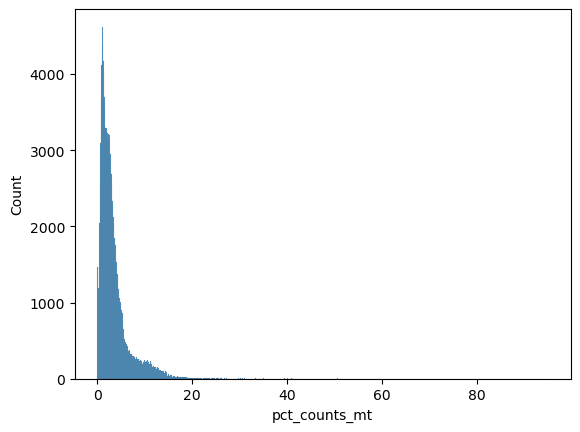

In [78]:
sns.histplot(adata.obs.pct_counts_mt)
plt.show()

In [79]:
adata = adata[adata.obs.pct_counts_mt <= 15].copy()

In [80]:
adata.layers["raw_counts"] = adata.X.copy()

## Normalize data (scanpy)

In [81]:
# Scanpy preprocessing pipeline
adata.raw = adata
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.layers["log1p"] = adata.X.copy()

# scVI training

In [82]:
# Setup scVI model using raw counts and batch info
scvi.model.SCVI.setup_anndata(
    adata,
    layer="raw_counts",
    batch_key="batch",
)
model = scvi.model.SCVI(adata)

In [83]:
# Train scVI model
model.train(
    early_stopping=True,
    max_epochs=1000,
    accelerator="gpu",
    devices="auto" 
)

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/conda-global-envs/sc-genomics/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=31` in the `DataLoader` to improve performance.
/conda-global-envs/sc-genomics/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_w

Training:   0%|          | 0/1000 [00:00<?, ?it/s]

Monitored metric elbo_validation did not improve in the last 45 records. Best score: 8243.165. Signaling Trainer to stop.


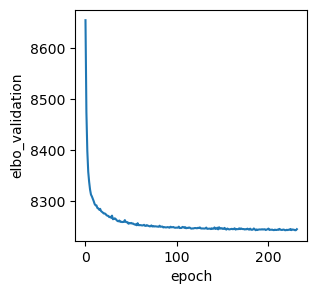

In [84]:
# Plot model ELBO
plt.figure(figsize=(3,3))
ax = sns.lineplot(model.history['elbo_validation'])
plt.ylabel("elbo_validation")
ax.get_legend().remove()
plt.show()

In [85]:
# get scVI latent space and normalized expression
adata.obsm["X_scVI"] = model.get_latent_representation()
adata.layers["scVI_normalized"] = model.get_normalized_expression(library_size=1e4)

In [86]:
# Dimensionality reduction
sc.pp.neighbors(adata, use_rep="X_scVI")

In [87]:
sc.tl.umap(adata, min_dist=0.1)

... storing 'batch' as categorical
... storing 'genotype' as categorical
... storing 'dataset' as categorical
... storing 'sample' as categorical
... storing 'strain' as categorical
... storing 'age' as categorical
... storing 'gene_biotype' as categorical


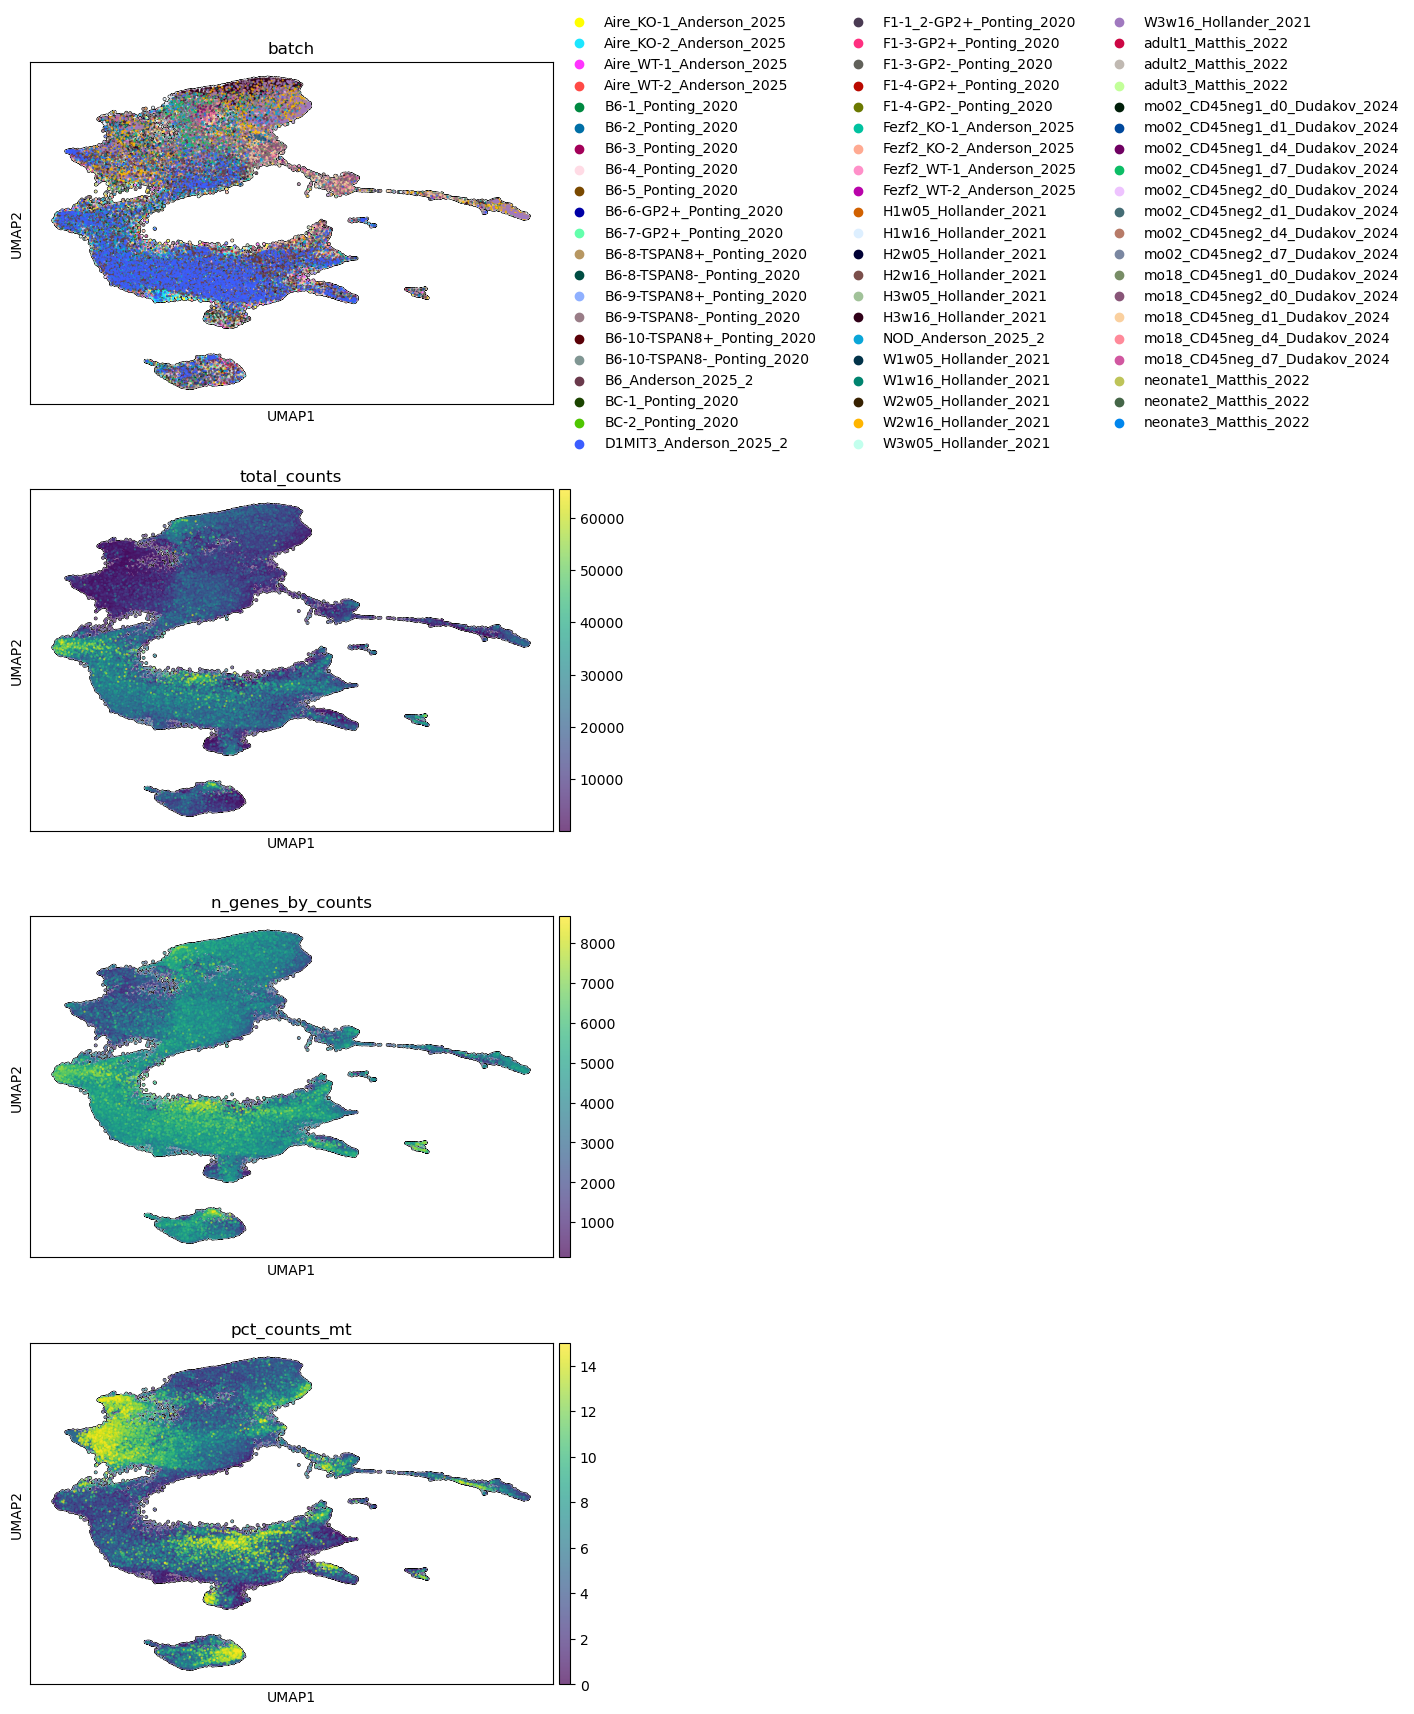

In [88]:
sc.pl.umap(
    adata,
    color=["batch", "total_counts", "n_genes_by_counts", "pct_counts_mt"],
    s=10,
    add_outline=True,
    ncols=1
)

# Consensus labels

In [89]:
adata.X = adata.layers["log1p"]

In [98]:
alignment = cellhint.harmonize(
    adata,
    dataset='dataset',
    cell_type='original_cell_type',
    use_rep="X_scVI",
    metric="euclidean",
    filter_cells=False,
)

🏆 Reordering datasets
🖇 Harmonizing cell types of Dudakov_2024 and Hollander_2021
🖇 Harmonizing cell types of Anderson_2025_2
🖇 Harmonizing cell types of Ponting_2020
🖇 Harmonizing cell types of Matthis_2022
🖇 Harmonizing cell types of Anderson_2025
🖋️ Reannotating cells
✅ Harmonization done!


In [99]:
alignment.relation

,Dudakov_2024,relation,Hollander_2021,relation,Anderson_2025_2,relation,Ponting_2020,relation,Matthis_2022,relation,Anderson_2025
0,11:aaTEC2,=,nTEC,=,NONE,=,NONE,=,NONE,=,NONE
0,NONE,=,NONE,=,NONE,=,NONE,=,NONE,=,Basal
0,12:cTEC,=,PerinatalcTEC,=,adult cTEC,=,NONE,=,adult cTEC,=,adult cTEC
1,12:early Pr,=,MaturecTEC,=,UNRESOLVED,=,NONE,=,perinatal cTEC,=,Immature MEC - Bcam
2,14:mTEC-prol,=,ProliferatingTEC,=,TA MEC,=,TA MEC,=,TA MEC,=,TA MEC
3,15:mTEC2,∈,MaturemTEC,=,Aire-stage,=,Aire-stage,=,Aire-stage,=,Aire-stage
4,16:mimetic(basal),=,PostAIREmTEC,∋,"Lung, basal",∈,"Lung, basal",=,"Lung, basal",=,Parabasal1
5,16:mimetic(basal),=,PostAIREmTEC,∋,"Skin, basal",∈,"Skin, basal",∋,"Skin, basal",=,"Skin, basal"
6,17:mimetic(tuft),=,TuftLikeTEC,∋,Tuft1,=,Tuft1,=,Tuft1,=,Tuft1
7,17:mimetic(tuft),=,TuftLikeTEC,∋,Tuft2,=,Tuft2,=,Tuft2,=,Tuft2


In [101]:
alignment.reannotation["reannotation"].unique()

array(['20:mimetic(microfold) ∈ MaturemTEC = Gut/Liver ∋ Gut/Liver = Gut/Liver = Gut/Liver',
       'UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED = Parabasal2',
       '15:mTEC2 ∈ MaturemTEC = Aire-stage = Aire-stage = Aire-stage = Aire-stage',
       '13:mTEC1 = IntertypicalTEC = Immature MEC = Immature MEC = Immature MEC ∋ Immature MEC - Ccl21',
       '20:mimetic(microfold) ∈ MaturemTEC = Gut/Liver ∋ Mcell = Mcell = Mcell',
       'UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED = Ciliated ∋ Div_ciliated',
       '13:mTEC1 = IntertypicalTEC = Immature MEC = Immature MEC = Immature MEC ∋ Immature MEC - Zeb1',
       '17:mimetic(tuft) = TuftLikeTEC ∋ Tuft2 = Tuft2 = Tuft2 = Tuft2',
       'UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED = Ciliated ∋ Ciliated',
       'UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED = Parabasal3',
       '17:mimetic(tuft) = TuftLikeTEC ∋ Tuft1 = Tuft1 = Tuft1 = Tuft1',
       'UNRESOLVED = UNRESOLVED = Skin, keratin

In [108]:
reannotation_dict = {
    'UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED = Ptf1a+ ductal = UNRESOLVED': "Ptf1a+ ductal",
    'UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED = Parabasal2': "Lung parabasal 2",
    '15:mTEC2 ∈ MaturemTEC = Aire-stage = Aire-stage = Aire-stage = Aire-stage': "Aire-stage",
    '20:mimetic(microfold) ∈ MaturemTEC = Gut/Liver ∋ Gut/Liver = Gut/Liver = Gut/Liver': "Gut+Liver",
    '13:mTEC1 = IntertypicalTEC = Immature MEC = Immature MEC = Immature MEC ∋ Immature MEC - Ccl21': "Intertypical TEC (Ccl21)",
    '20:mimetic(microfold) ∈ MaturemTEC = Gut/Liver ∋ Mcell = Mcell = Mcell': "M cell",
    'UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED = Ciliated ∋ Div_ciliated': "Div ciliated",
    '13:mTEC1 = IntertypicalTEC = Immature MEC = Immature MEC = Immature MEC ∋ Immature MEC - Zeb1': "Intertypical TEC (Zeb1)",
    '17:mimetic(tuft) = TuftLikeTEC ∋ Tuft2 = Tuft2 = Tuft2 = Tuft2': "Tuft 2",
    'UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED = Ciliated ∋ Ciliated': "Ciliated",
    'UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED = Parabasal3': "Lung parabasal 3",
    '17:mimetic(tuft) = TuftLikeTEC ∋ Tuft1 = Tuft1 = Tuft1 = Tuft1': "Tuft 1",
    'UNRESOLVED = UNRESOLVED = Skin, keratinized ∈ Skin, basal = UNRESOLVED = Skin, keratinized': "Keratinized skin",
    '16:mimetic(basal) = PostAIREmTEC ∋ Skin, basal ∈ Skin, basal ∋ Skin, keratinized = UNRESOLVED': "Keratinized skin",
    '16:mimetic(basal) = PostAIREmTEC ∋ Skin, basal ∈ Skin, basal ∋ Skin, basal = Skin, basal': "Basal skin",
    '19:mimetic(goblet) = UNRESOLVED = Goblet ∈ Lung, basal = Goblet ∋ Club_Goblet': "Club+Goblet",
    '19:mimetic(goblet) = UNRESOLVED = Goblet ∈ Lung, basal = Goblet ∋ Club_Serous': "Club+Serous",
    '12:early Pr = MaturecTEC = UNRESOLVED = NONE = perinatal cTEC = Immature MEC - Bcam': "Early prog",
    '14:mTEC-prol = ProliferatingTEC = TA MEC = TA MEC = TA MEC = TA MEC': "TA MEC",
    'NONE = NONE = NONE = Muscle = Muscle = Myoepithelial': "Myoepithelial",
    '16:mimetic(basal) = PostAIREmTEC ∋ Lung, basal ∈ Lung, basal = Lung, basal = Parabasal1': "Lung parabasal 1",
    '18:mimetic(neuroendo) = sTEC = Neuroendocrine = Neuroendocrine = Neuroendocrine = Neuroendocrine': "Neuroendocrine",
    '12:cTEC = PerinatalcTEC = adult cTEC = NONE = adult cTEC = adult cTEC': "cTEC",
    'NONE = NONE = NONE = NONE = NONE = Basal': "Basal lung",
    '10:aaTEC1 = NONE = UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED': "aaTEC1",
    '11:aaTEC2 = nTEC = NONE = NONE = NONE = NONE': "aaTEC2_nTEC",
    'UNRESOLVED = UNRESOLVED = UNRESOLVED = UNRESOLVED = Ionocyte = Ionocyte': "Ionocyte"
}
adata.obs["consensus_cell_type"] = alignment.reannotation["reannotation"].map(reannotation_dict)

In [109]:
adata.obs.loc[
    adata.obs.consensus_cell_type.isin(["aaTEC2_nTEC"]),
    "consensus_cell_type"
] = adata[adata.obs.consensus_cell_type.isin(["aaTEC2_nTEC"])].obs.original_cell_type

In [110]:
adata.obs.consensus_cell_type = adata.obs.consensus_cell_type.astype("category")
adata.obs.consensus_cell_type = adata.obs.consensus_cell_type.cat.rename_categories({"11:aaTEC2": "aaTEC2"})

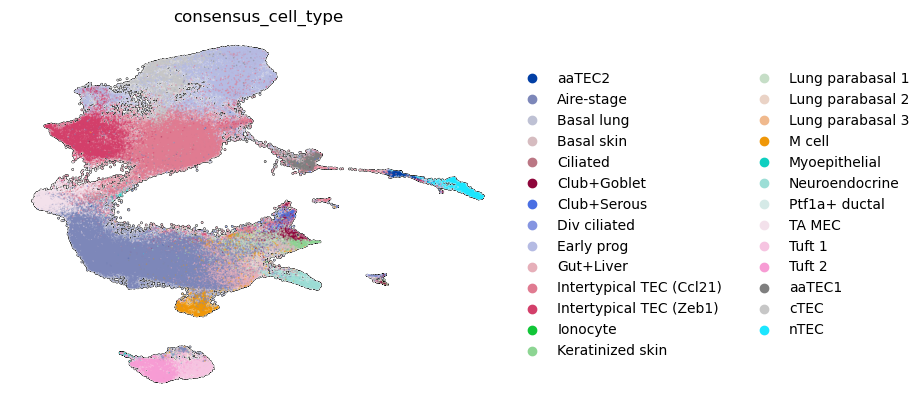

In [114]:
sc.pl.umap(
    adata,
    color=["consensus_cell_type"],
    s=5,
    add_outline=True,
    ncols=1,
    alpha=0.5,
    frameon=False
)

# Save data

In [115]:
# Check save paths
if not os.path.isdir(f"{processedDataPath}/Aire_atlas/scVI_models"):
    os.makedirs(f"{processedDataPath}/Aire_atlas/scVI_models")
    
if not os.path.isdir(f"{processedDataPath}/Aire_atlas/h5ad_files"):
    os.makedirs(f"{processedDataPath}/Aire_atlas/h5ad_files")
    
if os.path.isdir(f"{processedDataPath}/Aire_atlas/scVI_models/combined_all_genes"):
    shutil.rmtree(f"{processedDataPath}/Aire_atlas/scVI_models/combined_all_genes")
    
model.save(f"{processedDataPath}/Aire_atlas/scVI_models/mTEC_combined_all_genes")
adata.write(f"{processedDataPath}/Aire_atlas/h5ad_files/mTEC_combined_all_genes.h5ad")
alignment.write(f"{processedDataPath}/Aire_atlas/mTEC_cell_type_alignment.pkl")

In [149]:
adata = sc.read(f"{processedDataPath}/Aire_atlas/h5ad_files/mTEC_combined_all_genes.h5ad")

# Export data for atlas

In [118]:
scvi_atlas_data = pd.DataFrame(adata.layers["scVI_normalized"], index=adata.obs_names, columns=adata.var_names)
log1p_atlas_data = pd.DataFrame(adata.layers["log1p"].todense(), index=adata.obs_names, columns=adata.var_names)

In [123]:
scvi_atlas_data = pd.concat([scvi_atlas_data, adata.obs[['batch', 'genotype', 'original_cell_type', 'dataset', 'sample', 'strain', 'age', 'consensus_cell_type']]], axis=1)
log1p_atlas_data = pd.concat([log1p_atlas_data, adata.obs[['batch', 'genotype', 'original_cell_type', 'dataset', 'sample', 'strain', 'age', 'consensus_cell_type']]], axis=1)

In [127]:
scvi_atlas_data["x"] = [i[0] for i in adata.obsm["X_umap"]]
scvi_atlas_data["y"] = [i[1] for i in adata.obsm["X_umap"]]
log1p_atlas_data["x"] = [i[0] for i in adata.obsm["X_umap"]]
log1p_atlas_data["y"] = [i[1] for i in adata.obsm["X_umap"]]

In [131]:
scvi_atlas_data = scvi_atlas_data.apply(lambda col: col.astype(str) if col.dtype.name == "category" else col)
log1p_atlas_data = log1p_atlas_data.apply(lambda col: col.astype(str) if col.dtype.name == "category" else col)

In [132]:
scvi_atlas_data.to_hdf(f"{processedDataPath}/Aire_atlas/mTEC_scVI.h5", key="data")
log1p_atlas_data.to_hdf(f"{processedDataPath}/Aire_atlas/mTEC_log1p.h5", key="data")